# Problem — a relative focal-depth field from a real focal stack

We reconstruct a full1080×1920 field from **all19 real author-registered Nexus5 frames**. The selected method is the degree8 variational depth-from-focus CUDA port accompanying Möller et al., IEEE TIP2015, doi:10.1109/TIP.2015.2479469. The later author's smartphone dataset is distinct from the paper's ARRI and synthetic examples. This review preserves their relevant comparisons, without claiming to recreate the original paper figures.

The unknown is a dimensionless relative best-focus coordinate, **not metric scene depth**. There is no independently measured depth truth. The independently run original method is a method reference; its outputs are never called ground truth. Every fresh result below is computed in this notebook from the public observations, using only the cleaned local modules.


In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,HTML
root=Path.cwd()
if not (root/'src').is_dir(): root=root.parent
assert (root/'src').is_dir()
sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.solvers import reconstruct,linearized_admm,classical_focus,tv_denoise_only
from src.physics_model import objective
from src.visualization import make_figures,image_metrics
start=time.perf_counter()


# Data — complete native acquisition and source measurements

Public `observations` has batch-first shape(1,19,1080,1920,3), uint8 DN, BGR channels. No reconstructed scene or target-derived calibration is present. The frame order is native balcony_0002 through balcony_0020. Existing author registration is retained, with no additional warp, crop, downsampling or padding. Plot-only decimation is labeled separately.

The upstream reference came from a complete independent unmodified CUDA CLI run. Two additional actual source runs independently characterize compiler FMA sensitivity and a qualified initialization change. They are loaded **only as identified comparisons**, after which the local primary and comparison methods run afresh. The extra source runs do not establish optical depth truth.


In [2]:
images=load_observations(root/'data/raw_data.npz')
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False) as f: upstream=f['reconstruction'][0]
with np.load(root/'notebooks/reference_outputs/source_diagnostics.npz',allow_pickle=False) as f:
    source_diagnostics={k:f[k] for k in f.files}
print('Actual observations:',images.shape,images.dtype,'DN; full frames:',len(images))
print('Source reference is conditional algorithm output; metric depth truth is unavailable.')


Actual observations: (19, 1080, 1920, 3) uint8 DN; full frames: 19
Source reference is conditional algorithm output; metric depth truth is unavailable.


# Physics — defocus evidence and its identification limit

For image location r, frame k, latent radiance L, camera focus f, scene depth z and defocus point-spread function h, the local optical model is

$$I_k(\mathbf r)=[h_{z(\mathbf r),f_k}*L](\mathbf r)+\eta_k(\mathbf r).$$

I denotes the acquired three-channel digital intensity, * is convolution and eta collects noise/model errors. No calibrated h or metric lens settings are supplied. We can identify only an image-order best-focus coordinate, defined by

$$t_k=20(k/18-1/2),\quad k=0,\ldots,18.$$

These nodes do not imply equal physical focus-distance steps. Higher index is not asserted to mean a known near/far direction. Texture, saturation, occlusion and registration/photometric effects limit local focus evidence. Consequently fitted contrast and spatial smoothness are model diagnostics, not a physical distance error.


# Method — actual local mathematics and the retained source discrepancy

Each BGR channel is multiplied by binary32(1/255). With replicate image boundaries, the focus score S sums absolute horizontal and vertical central second differences over all three channels. Normalize by multiplying by 1/(max(S)+0.3), per pixel. Fit a degree8 contrast polynomial C using the source's explicit binary32 monomial normal equations. The design's condition number is approximately8.93×10^7; this selected port has a genuine numerical limitation. Local partial-pivoted elimination and original accumulation conventions preserve its result, rather than silently changing to an SVD estimator.

For focal-coordinate field u, data weight a=6 and unit-pixel forward difference K, the selected objective is

$$E(u)=-a\sum_{\mathbf r}C_{\mathbf r}(u(\mathbf r))+\sum_{\mathbf r}\lVert Ku(\mathbf r)\rVert_2.$$

The original initializer smooths raw S with15×15 boxes, selects the first strict frame maximum, smooths those indices with a21×21 box and maps them to focal coordinates. **Port discrepancy:** its argmax is zero-based but scaling subtracts1, shifting the initializer by−20/18. We retain and explicitly identify this initialization convention. It does not shift the fitted focus nodes or output coordinates. An independently executed source variant corrects only that initialization and is shown separately. It reaches a different nonconvex solution, and the original even has slightly lower final conditional objective here; no physical superiority is inferred.

Let D=−C, tau=8/a, lambda=1, g=0 and b=0 initially. A local linearized ADMM iteration solves

$$v=(I+\lambda K^\mathsf{T}K)^{-1}[u-\tau aD'(u)+\lambda K^\mathsf{T}(g-b)],\quad u=\operatorname{clip}(v,-10,10),$$

$$q=Ku+b,\quad g=\max(1-\tau/(\lambda\lVert q\rVert_2),0)q,\quad b\leftarrow b+Ku-g.$$

At q=0 the shrinkage is zero. g is the split spatial gradient and b its scaled dual. The Neumann linear solve is explicitly diagonalized with cosine eigenvalues4sin²(pi p/(2H))+4sin²(pi q/(2W)); H,W are image height,width and p,q the respective mode indices. The repeated symbol q in the eigenvalue expression denotes a column mode only, rather than the vector shrinkage argument. Source lambda increases by1.02 after zero-based iteration>0 and b is rescaled inversely. We execute **all400steps**. There is no claimed global minimizer or inferred tolerance convergence. Clipping preserves a source safeguard, not an exact constrained coupled quadratic proximal map. The paper's inconsistent printed split/dual terms are resolved by the actual source and an independent augmented-term derivation, with no silent sign changes.


In [3]:
primary_start=time.perf_counter()
def progress(n,u):
    if n in (1,100,200,300,400):print('Fresh primary iteration',n,'elapsed',round(time.perf_counter()-primary_start,3),'s')
fresh,details=reconstruct(images,callback=progress)
primary_seconds=time.perf_counter()-primary_start
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
fresh_metrics=image_metrics(fresh,upstream)
print('Full primary reconstruction seconds:',primary_seconds)
print('Fresh versus original:',fresh_metrics)
print('Conditional objective:',details['objective'])


Fresh primary iteration 1 elapsed 128.377 s
Fresh primary iteration 100 elapsed 147.825 s
Fresh primary iteration 200 elapsed 167.274 s
Fresh primary iteration 300 elapsed 186.689 s
Fresh primary iteration 400 elapsed 207.021 s
Full primary reconstruction seconds: 207.25358150000102
Fresh versus original: {'ncc': 0.9999999999434068, 'nrmse': 2.736546037599222e-06}
Conditional objective: {'negative_contrast': -319273.7157002305, 'tv': 54330.08339856921, 'objective': -1861312.2108028138}


# Results — preserve meaningful scientific comparison groups

We now compute four classical estimates from the full fresh19-frame sharpness array: unsmoothed MLAP,9×9 windowing,41×41 windowing followed by11×11 median, and21×21 windowing followed by5×5 median. The small/large-window and median comparisons preserve the paper's different noise/detail regimes. Separately, three additional complete400-step joint solves use a=4,12,28, corresponding to TV/data weights1/4,1/12,1/28 after dividing the objective by a. The selected main a=6 stays fixed. No comparison fills an uncomputed result or supplies another method's cached reconstruction.

Two explicit250-step primal-dual ROF solves apply TV only **after** the21/median5 estimate, at weights6and26 in this task's relative-coordinate units. This retains the scientific difference between joint inference and denoising an already selected focus image. The later dataset and coordinate scale prevent claiming identical numerical paper experiments. The ROF outputs are fixed-budget numerical comparisons, not claimed exact optima.


In [4]:
comparison_start=time.perf_counter()
classical={
 'Unsmoothed MLAP':classical_focus(details['sharpness'],1),
 'MLAP9×9':classical_focus(details['sharpness'],9),
 'MLAP41×41 + median11×11':classical_focus(details['sharpness'],41,11),
 'MLAP21×21 + median5×5':classical_focus(details['sharpness'],21,5)}
variants={}
for a in (4.,12.,28.):
    variants[a],_=linearized_admm(details['derivative'],details['initial'],iterations=400,data_fidelity=a,capture_steps=())
    print('Fresh complete variational comparison a=',a,'elapsed',round(time.perf_counter()-comparison_start,2),'s')
tv_only={weight:tv_denoise_only(classical['MLAP21×21 + median5×5'],weight,250) for weight in (6.,26.)}
comparison_seconds=time.perf_counter()-comparison_start
print('All fresh scientific comparisons seconds:',comparison_seconds)


Fresh complete variational comparison a= 4.0 elapsed 80.08 s
Fresh complete variational comparison a= 12.0 elapsed 157.77 s
Fresh complete variational comparison a= 28.0 elapsed 233.59 s
All fresh scientific comparisons seconds: 265.789254599993


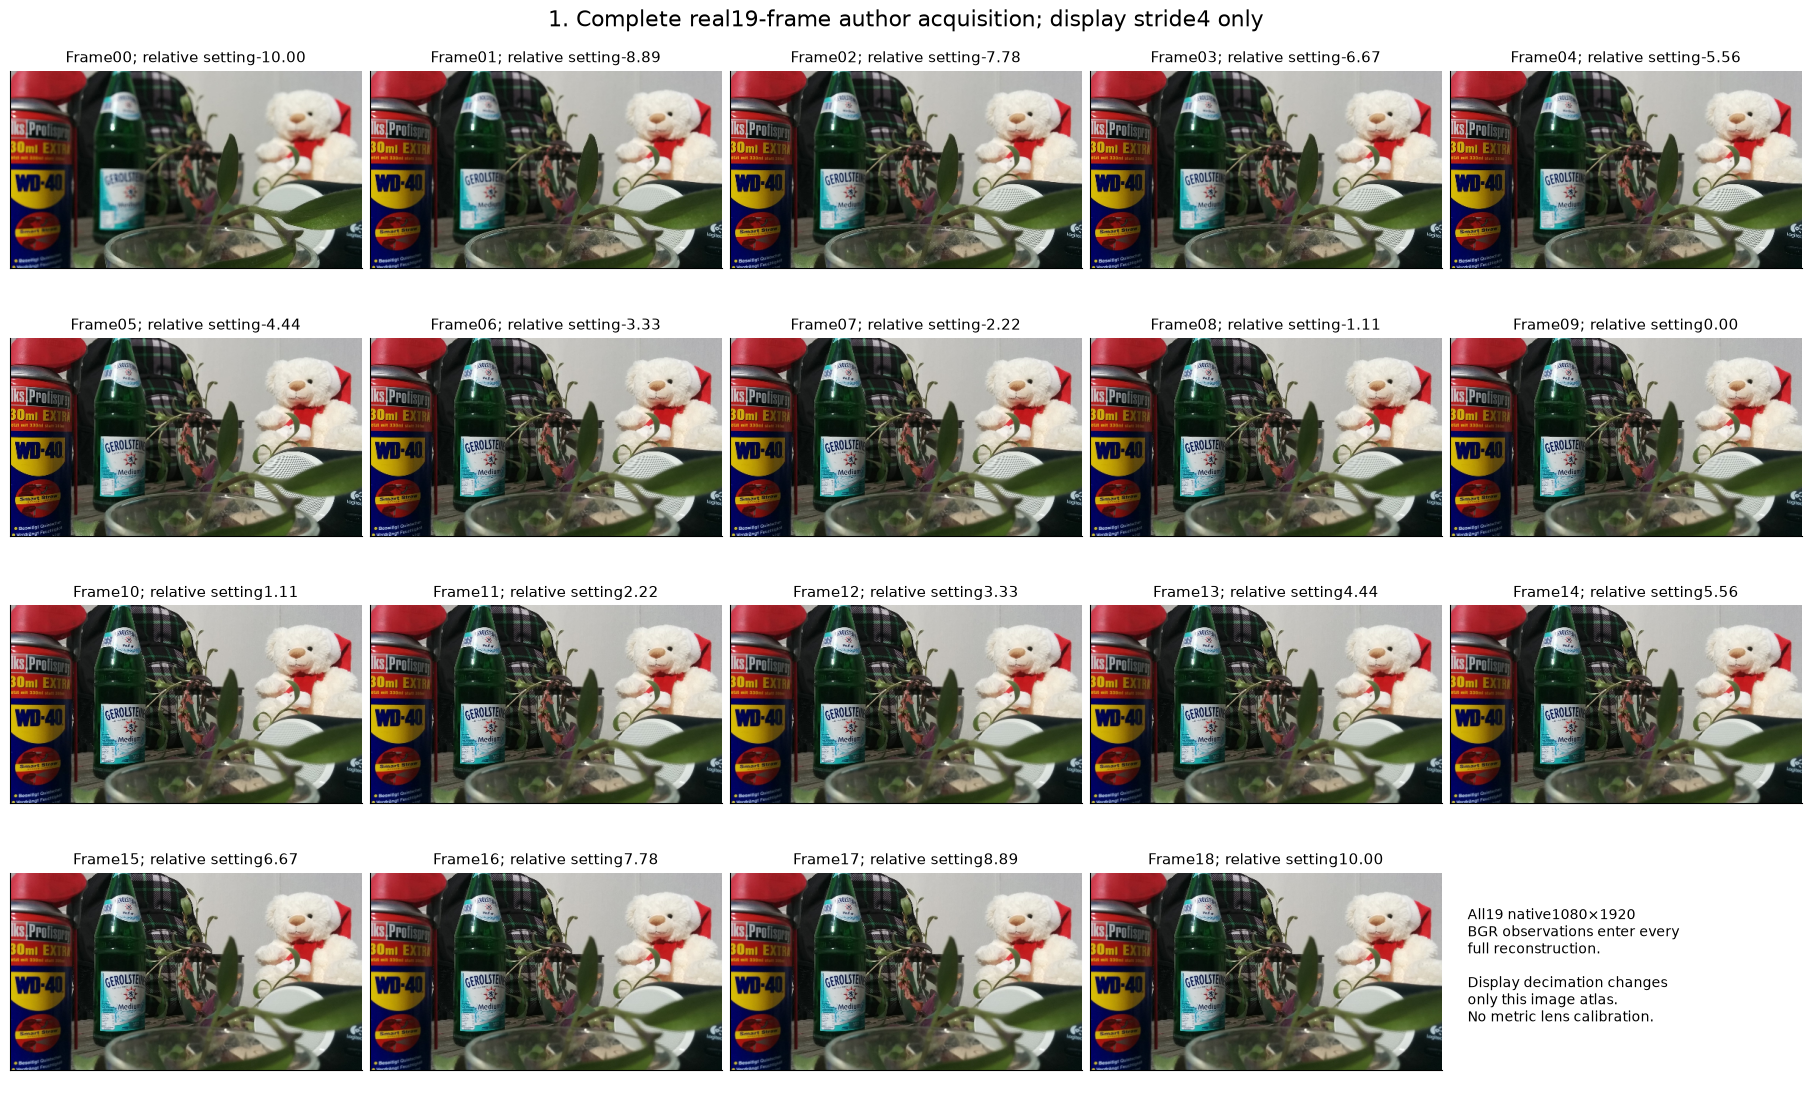

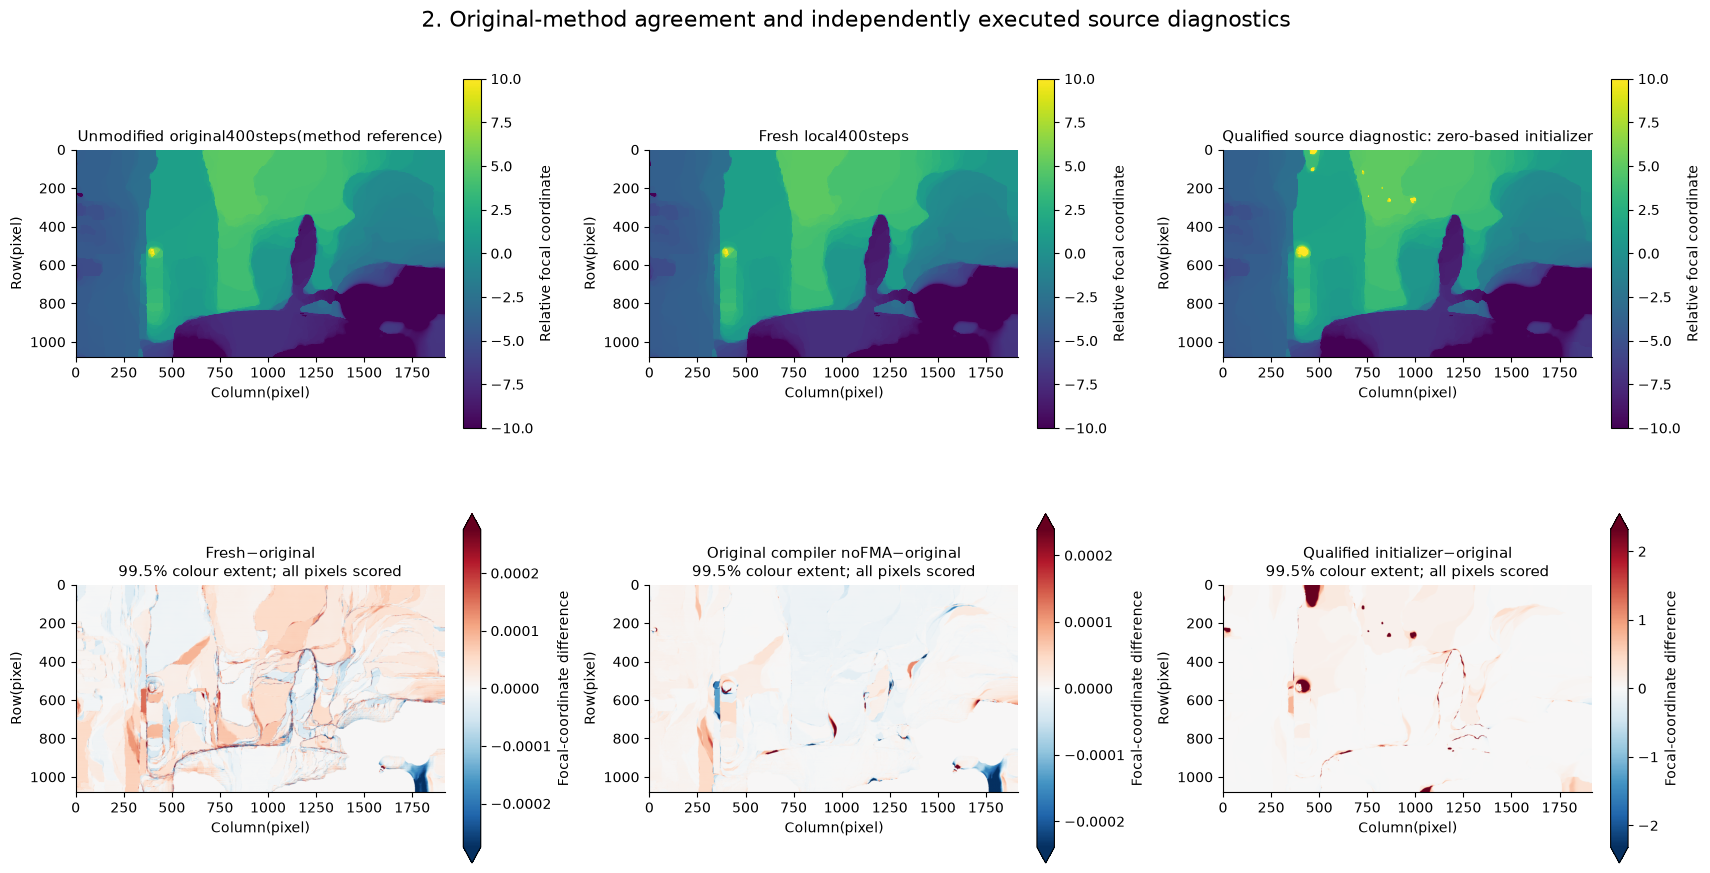

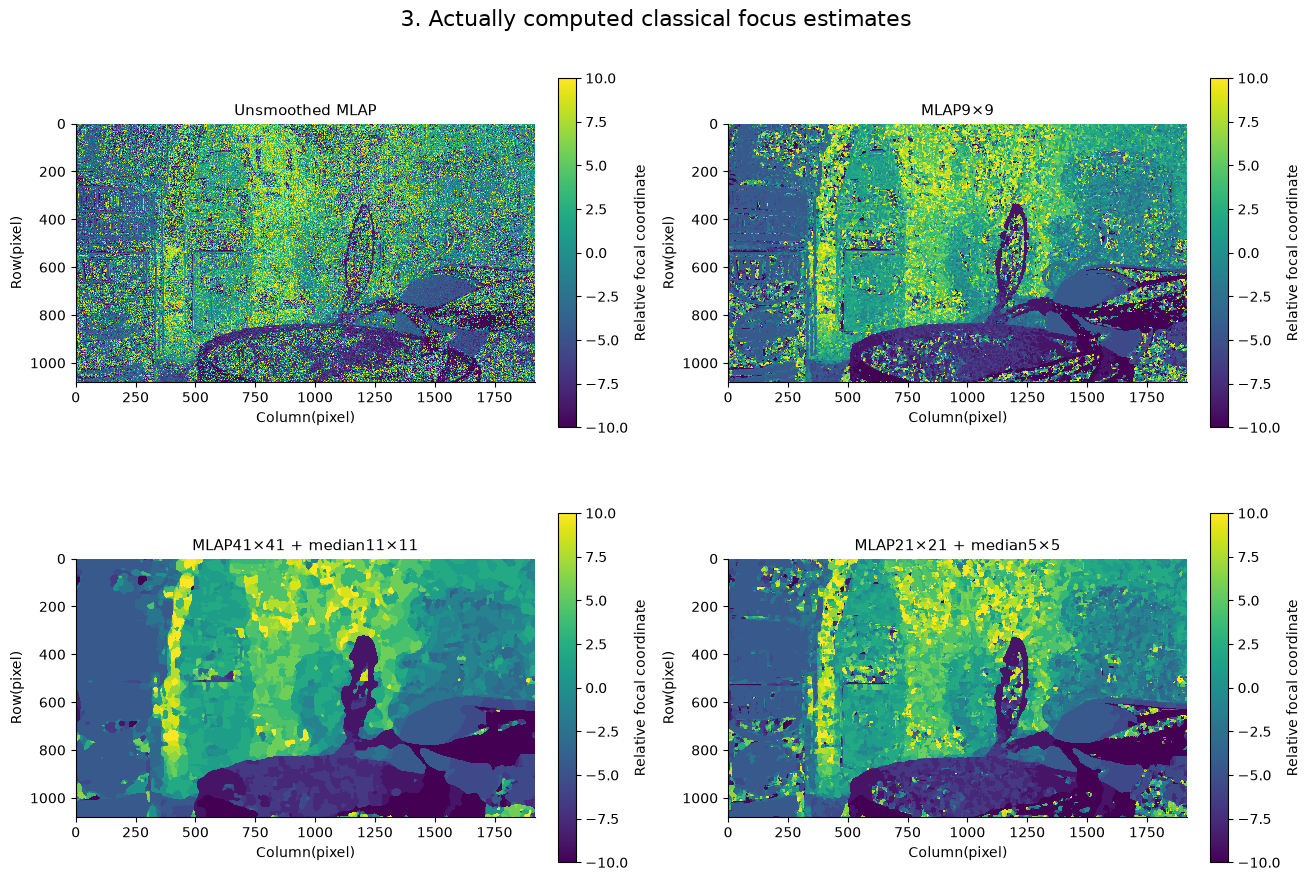

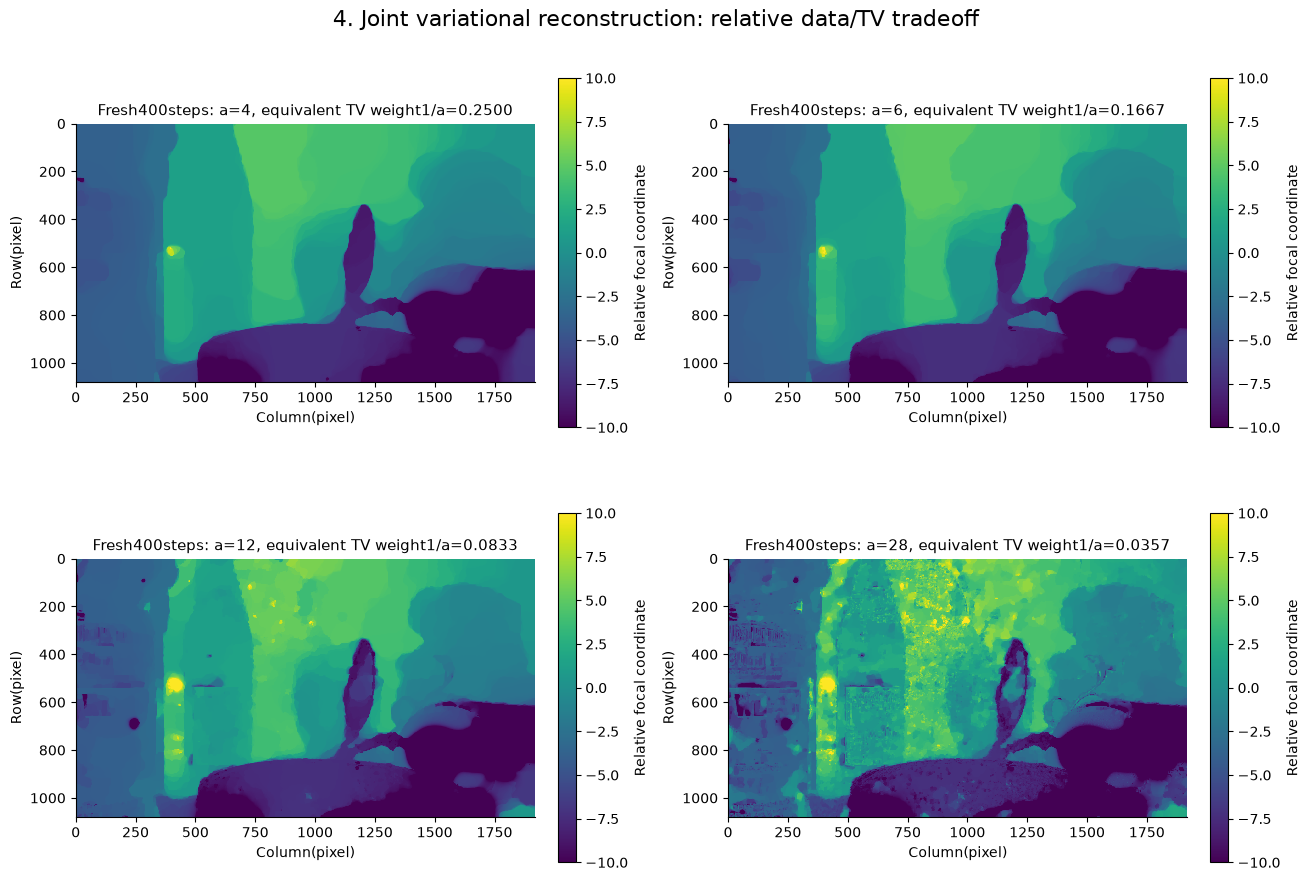

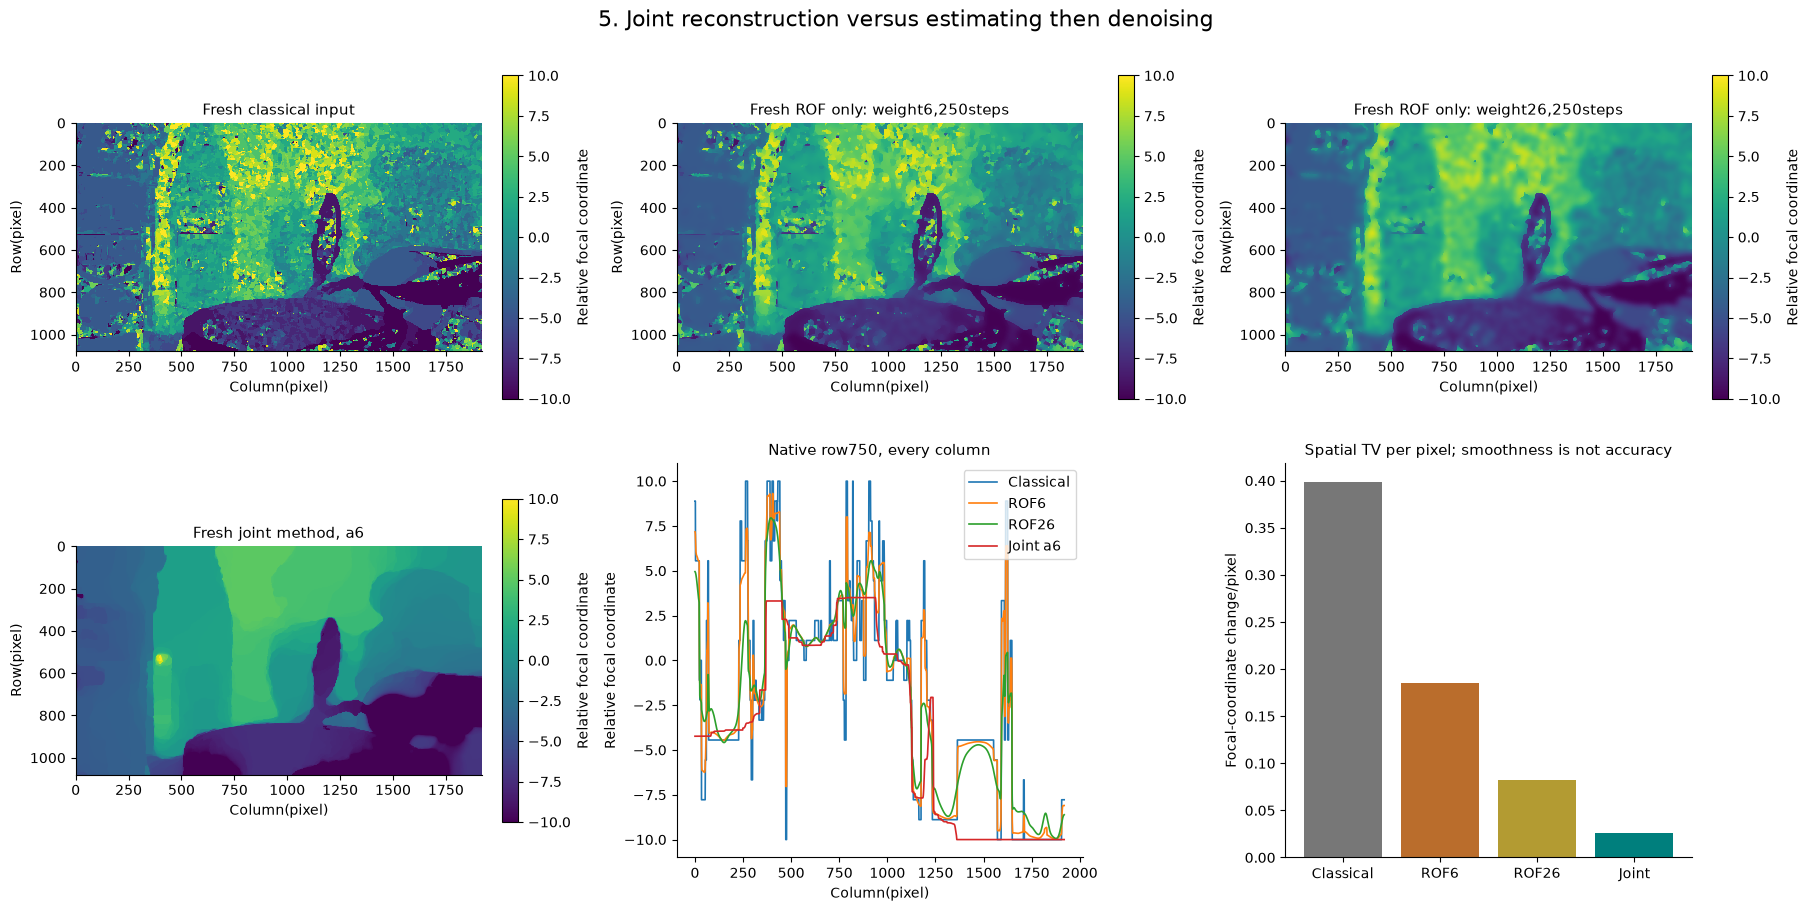

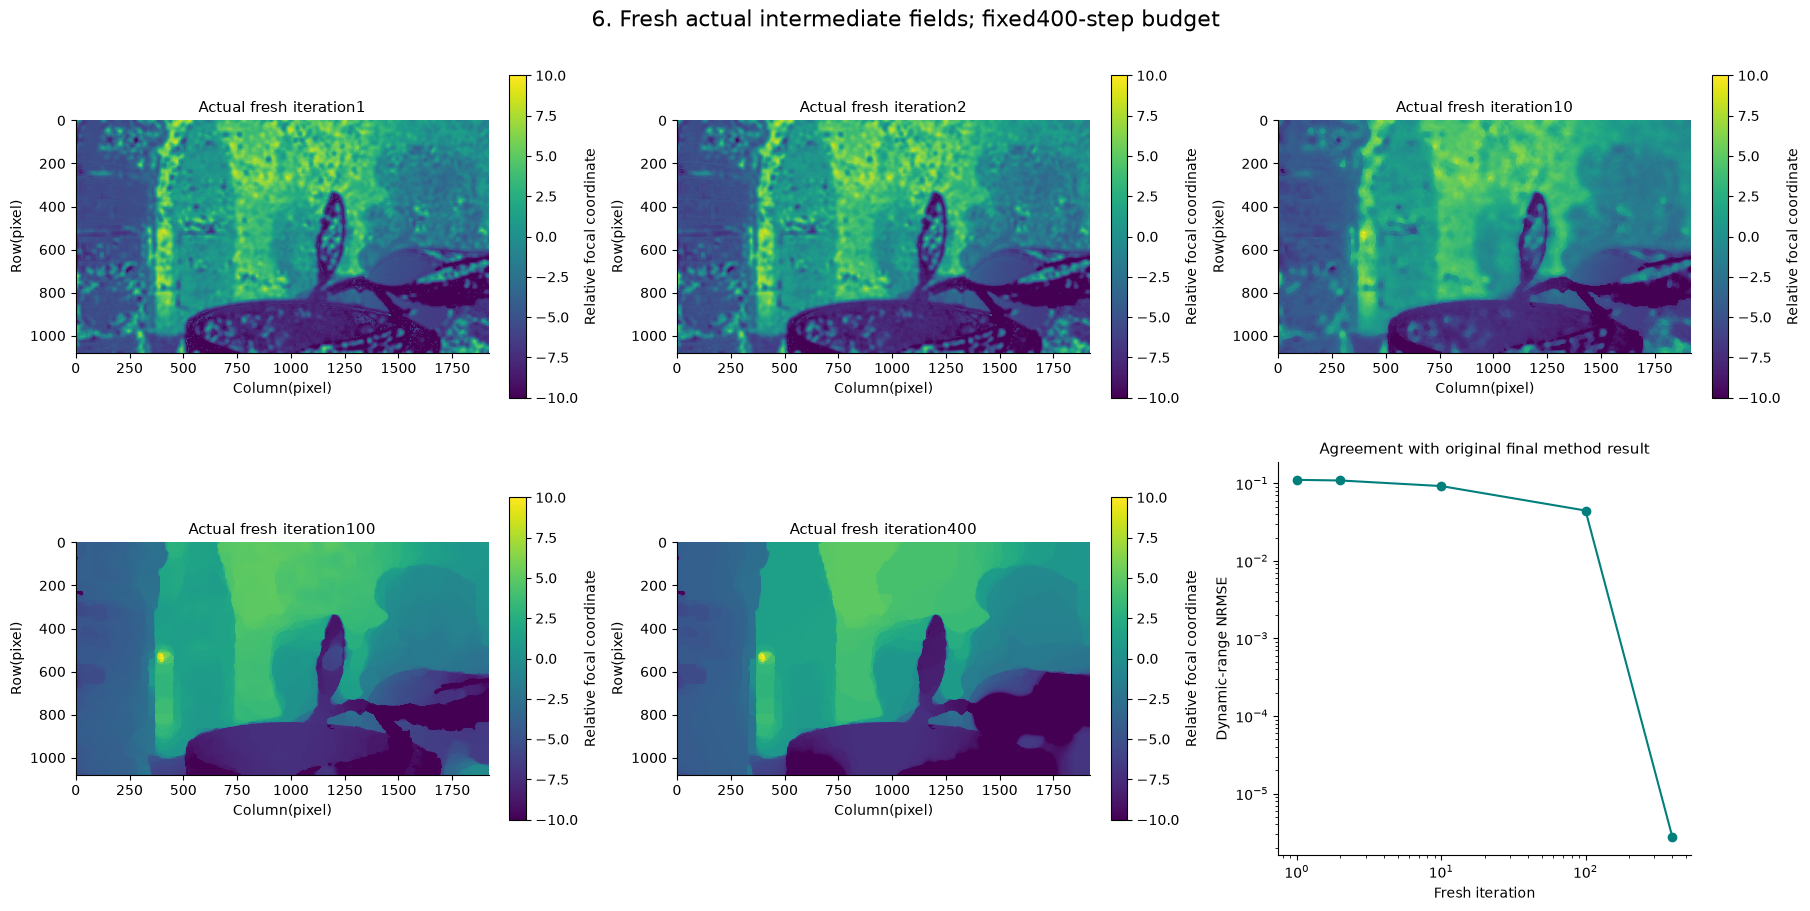

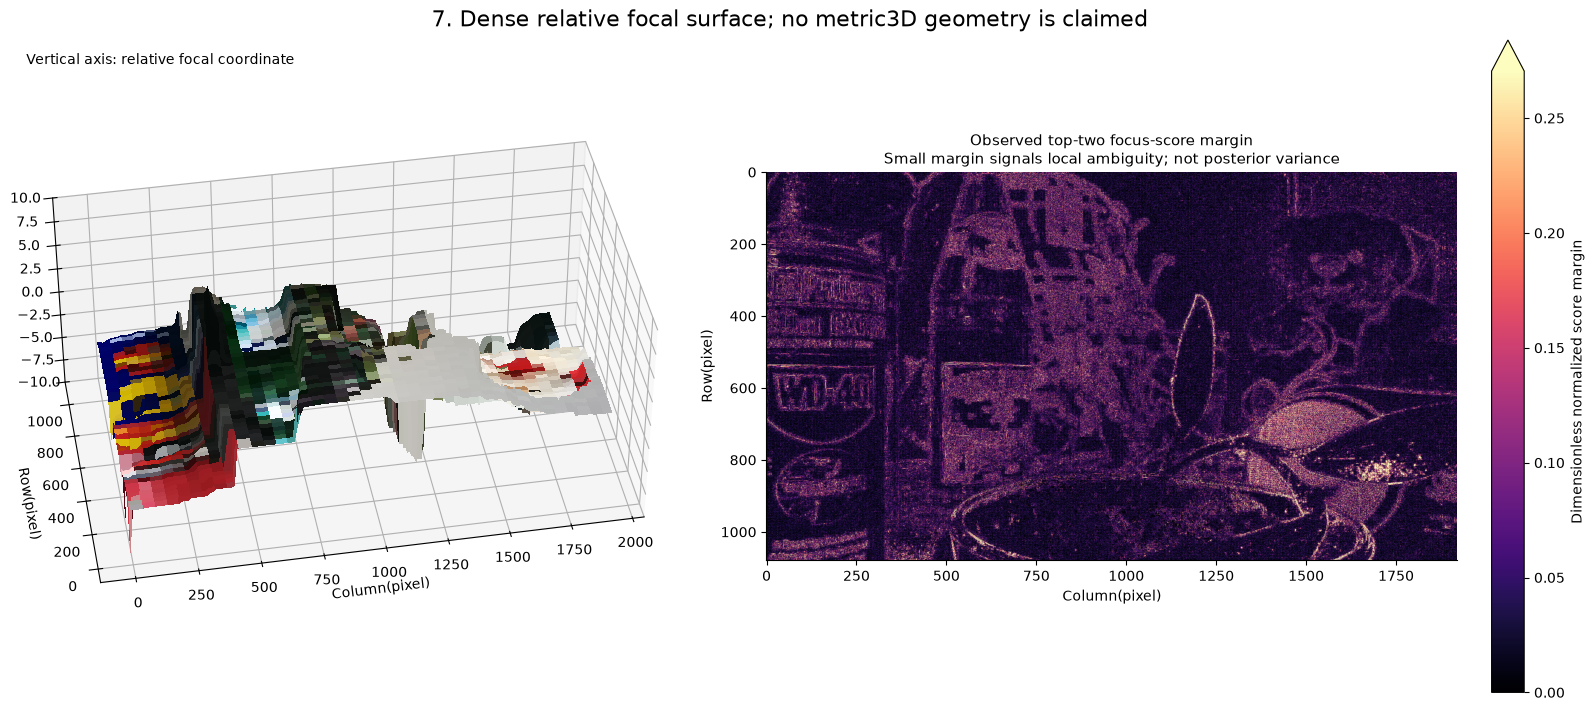

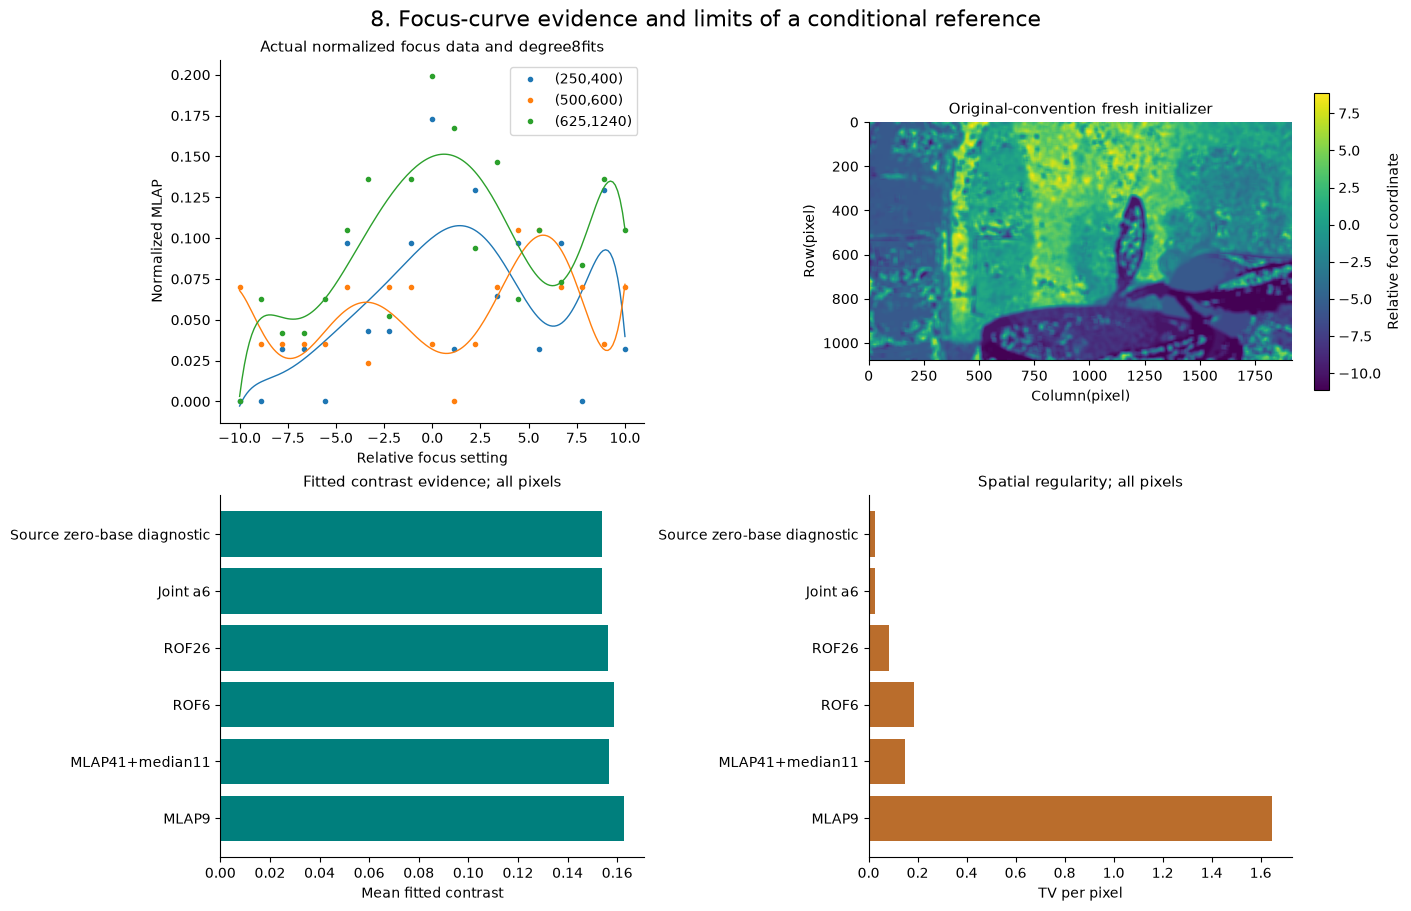

In [5]:
export=os.environ.get('IMAGING_REVIEW_EXPORT')
figures,measurements,captions=make_figures(images,fresh,details,upstream,source_diagnostics,classical,variants,tv_only,export)
for figure,caption in zip(figures,captions):
    display(figure)
    display(HTML('<p>'+caption+'</p>'))
    plt.close(figure)


In [6]:
rows=[]
for name,m in measurements.items():
    rows.append('<tr><td>'+name+'</td><td>'+format(m['ncc'],'.10f')+'</td><td>'+format(m['nrmse'],'.8g')+'</td><td>'+format(m['objective'],'.8g')+'</td></tr>')
display(HTML('<p>Conditional reference agreement; not a physical-depth accuracy ranking.</p><table><tr><th>Actually computed method/oracle diagnostic</th><th>Cosine NCC</th><th>Range NRMSE</th><th>Common a6 objective</th></tr>'+''.join(rows)+'</table>'))
import subprocess
command=[sys.executable,str(root/'evaluation/judge.py'),'--prediction',str(root/'output/reconstruction.npz'),'--report',str(root/'output/judge_report.json')]
run=subprocess.run(command,capture_output=True,text=True)
assert run.returncode==0,(run.stdout,run.stderr)
judge=json.loads((root/'output/judge_report.json').read_text())
assert judge['passed']
print('Fresh standalone Judge:',judge)
print('Primary seconds:',primary_seconds,'comparison seconds:',comparison_seconds,'total seconds:',time.perf_counter()-start)


Actually computed method/oracle diagnostic,Cosine NCC,Range NRMSE,Common a6 objective
fresh_main_a6,0.9999999999,2.736546e-06,-1861312.2
classical_Unsmoothed MLAP,0.3927003424,0.29931331,13083791
classical_MLAP9×9,0.6553008247,0.22155876,1391050.4
classical_MLAP41×41 + median11×11,0.8778852536,0.12892087,-1647014.3
classical_MLAP21×21 + median5×5,0.8087681251,0.16270841,-1152057.4
fresh_variational_a4,0.9980917099,0.016043028,-1862102
fresh_variational_a12,0.9889610240,0.038556678,-1842159
fresh_variational_a28,0.9618056525,0.072415493,-1673319.4
fresh_rof_weight6,0.8522542270,0.13863669,-1589137
fresh_rof_weight26,0.9062522339,0.10828084,-1773401.5


Fresh standalone Judge: {'status': 'pass', 'passed': True, 'metrics': {'ncc': 0.9999999999434068, 'nrmse': 2.736546037599222e-06}, 'thresholds': {'ncc': {'comparison': 'greater_equal', 'boundary': 0.9999999997503717}, 'nrmse': {'comparison': 'less_equal', 'boundary': 7.00263889276999e-06}}, 'errors': []}
Primary seconds: 207.25358150000102 comparison seconds: 265.789254599993 total seconds: 535.2844530000002


# Conclusion — supported behavior and remaining ambiguity

The complete fresh native reconstruction and strict standalone evaluation above establish agreement with the independently executed selected published method. Independent stage fixtures, analytic focus/difference cases, gradient-adjoint identity, dense Neumann solves and proximal checks establish distinct numerical and mathematical evidence; Judge agreement alone is insufficient.

The comparisons show the actual tradeoff among local focus selection, median filtering, denoising after estimation and joint spatially regularized inference. Common signed/relative colour scales preserve comparability. All metrics score the full grid. Source compiler sensitivity, original initialization offset, nonconvex dependence, weak local focus evidence and boundary clipping remain visible. Surface plots have pixel x/y axes and a relative focal-coordinate vertical axis; they are not metrically calibrated scene geometry.

No independent physical depth truth is available. We therefore make no optical distance-error claim, superiority claim based solely on reference agreement, global convergence claim, or claim to reproduce the paper's different ARRI dataset. The canonical notebook's actual execution and all scientific figure exports are recorded in `test/validation.md` after validation.
